# 01 · 街景优先：抓 Mapillary 街景 → 落到 H3 格子（GreenPath）

**流程方向**：先有街景，再由街景所在位置决定"哪些格子进入数据集"。
（旧流程是先铺网格、再给每个格子找街景。反过来做的好处：不会浪费算力给没有街景的格子裁图，也能直接看到真实覆盖率。）

**这一步做什么**
1. 用 Mapillary 的矢量瓦片，批量下载试点区域内的街景**元数据**（位置、拍摄时间、朝向、是否全景、质量分）。
2. 过滤：太旧、冬季拍摄、全景图（暂不处理）、没有朝向信息的图。
3. 每张图算出所在的 H3 格子（`h3_index`），每个格子最多挑 4 张**朝向分散**的图。
4. 统计覆盖率：多少格子有 ≥1 / ≥2 张可用街景。
5. 从"街景足够"的格子里抽 `SAMPLE_SIZE` 个，下载图片，写出格子表。

| | 路径（相对数据根目录） |
|---|---|
| 输出：街景元数据（原始，按瓦片缓存） | `raw/mapillary/metadata/{city}/tile_z14_*.parquet` |
| 输出：街景图片 | `raw/mapillary/images/{image_id}.jpg` |
| 输出：完整网格（用于覆盖率统计） | `raw/grid/{city}_h3r{res}.parquet` |
| 输出：入选的街景 | `processed/streetview.parquet` |
| 输出：**格子主表** | `processed/cells.parquet` |
| 输出：运行记录 | `runs/{时间戳}/01_streetview_manifest.json` |

**之后的 notebook 都以 `h3_index` 为主键**，02 给这些格子裁卫星图，03 算 OSM / WorldCover 特征。

**需要**：Mapillary 的 client token（免费，https://www.mapillary.com/dashboard/developers 注册应用后获得，形如 `MLY|123|abc...`）。
本地运行：在项目根目录建一个 `.env` 文件（参考 `.env.example`），写一行 `MAPILLARY_TOKEN=MLY|...`；Colab：左侧 🔑 Secrets 里添加名为 `MAPILLARY_TOKEN` 的密钥。**`.env` 已在 `.gitignore` 里，不要把 token 写进 notebook 或提交到 git。**

**许可**：Mapillary 图片是 CC-BY-SA，发布数据集或成果时要注明来源。**不需要 GPU。** 可断点续跑。

## 1. 安装依赖（只在 Colab 里会执行）

In [ ]:
import sys, subprocess
if "google.colab" in sys.modules:      # 只有在 Colab 里才自动安装；本地环境请提前装好
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "h3>=4", "requests", "mapbox-vector-tile", "mercantile", "pandas", "pyarrow", "gcsfs", "shapely", "matplotlib", "pillow", "tqdm", "fsspec"], check=True)

## 2. 配置
所有参数都在这里。以后搬进容器时，这一格会变成 `configs/boston.yaml`。

- `BBOX`：试点范围（经度、纬度）。
- `TILE_ZOOM`：Mapillary 的街景点只在 zoom 14 的瓦片里提供，不要改。
- `MIN_QUALITY`：Mapillary 给每张图的质量分（0–1），低于它的丢弃；`0` = 不过滤。
- `MIN_YEAR` / `EXCLUDE_MONTHS`：只用较新的图；排除 12–3 月（落叶季会让树荫、自然感分数偏低）。
- `ALLOW_PANO`：全景图是等距柱状投影，直接丢给 VLM 会变形，先排除；以后可以切成 4 个 90° 视角再加回来。
- `MIN_IMAGES_PER_CELL` / `MAX_IMAGES_PER_CELL`：一个格子至少 2 张才算"有街景"，最多保留 4 张。
- `SAMPLE_SIZE`：从合格格子里抽多少个来下载图片。`0` = 全部。

In [ ]:
CITY = "boston"
CITY_PREFIX = "BOS"
BBOX = (-71.13, 42.33, -71.03, 42.39)   # (min_lon, min_lat, max_lon, max_lat)
H3_RES = 10                             # 每格约 130 m 宽

TILE_ZOOM = 14
MIN_QUALITY = 0.0
MIN_YEAR = 2019
EXCLUDE_MONTHS = (12, 1, 2, 3)
ALLOW_PANO = False
MIN_IMAGES_PER_CELL = 2
MAX_IMAGES_PER_CELL = 4

SAMPLE_SIZE = 0        # 0 = 全部合格格子
SEED = 42
DOWNLOAD_IMAGES = True
DOWNLOAD_WORKERS = 8      # 并发下载线程数（Mapillary 的限流很宽松，8–16 都可以）

STORAGE = "local"                              # "local" | "gcs" | "drive"
GCS_ROOT = "gs://greenpath-data"
DRIVE_ROOT = "/content/drive/MyDrive/greenpath-data"
LOCAL_ROOT = "./data"

## 3. 连接存储

In [ ]:
import os, io, json, datetime
import fsspec
import pandas as pd

STORAGE_OPTS = {}
if STORAGE == "gcs":
    try:
        from google.colab import auth
        auth.authenticate_user()                 # Colab 里登录；本地请先 gcloud auth application-default login
    except ImportError:
        pass
    ROOT = GCS_ROOT
    STORAGE_OPTS = {"token": "google_default"}
    fs = fsspec.filesystem("gcs", **STORAGE_OPTS)
elif STORAGE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = DRIVE_ROOT
    fs = fsspec.filesystem("file")
else:
    ROOT = os.environ.get("GREENPATH_ROOT", LOCAL_ROOT)   # 以后容器里用环境变量指定数据目录
    fs = fsspec.filesystem("file")

def path(*parts):
    # 拼出数据根目录下的完整路径，例如 path("processed", "cells.parquet")
    return "/".join([ROOT.rstrip("/"), *parts])

def makedirs(p):
    if STORAGE != "gcs":            # GCS 没有真正的目录，不需要创建
        os.makedirs(p, exist_ok=True)

def read_parquet(p):
    return pd.read_parquet(p, storage_options=STORAGE_OPTS or None)

def write_parquet(df, p):
    df.to_parquet(p, index=False, storage_options=STORAGE_OPTS or None)

def write_manifest(manifest, name):
    run_ts = datetime.datetime.utcnow().strftime("%Y-%m-%dT%H-%M")
    makedirs(path("runs", run_ts))
    with fs.open(path("runs", run_ts, name), "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)
    return manifest

try:                                          # 图里的中文用系统自带的中文字体显示
    import matplotlib
    matplotlib.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS", "Noto Sans CJK SC",
                                              "Microsoft YaHei", "SimHei", "DejaVu Sans"]
    matplotlib.rcParams["axes.unicode_minus"] = False
except ImportError:
    pass

now_iso = lambda: datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"
print("数据根目录:", ROOT)

数据根目录: ./data


In [ ]:
for d in ["raw/grid", "raw/mapillary/images", f"raw/mapillary/metadata/{CITY}", "processed", "runs"]:
    makedirs(path(d))

## 4. Mapillary token 和请求函数
网络请求都经过 `mapillary_get` / `download_bytes` 两个函数，遇到限流（429）或服务器错误会自动退避重试。

In [ ]:
import time, requests

def load_dotenv_file(name=".env"):
    # 从当前目录向上找 .env，把里面的 KEY=VALUE 读进环境变量（已经设置过的环境变量优先）
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, name)
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8"):
                line = line.strip()
                if line and not line.startswith("#") and "=" in line:
                    k, v = line.split("=", 1)
                    os.environ.setdefault(k.strip(), v.strip().strip("\"'"))
            return p
        if os.path.dirname(d) == d:
            return None
        d = os.path.dirname(d)

try:
    from google.colab import userdata
    TOKEN = userdata.get("MAPILLARY_TOKEN")
except Exception:
    load_dotenv_file()
    TOKEN = os.environ.get("MAPILLARY_TOKEN")
assert TOKEN, "没找到 MAPILLARY_TOKEN：本地请在项目根目录的 .env 里写 MAPILLARY_TOKEN=...，Colab 请在 Secrets 里添加"

API = "https://graph.mapillary.com"

class MapillaryError(RuntimeError):
    def __init__(self, status, body, auth=False):
        super().__init__(f"Mapillary 返回 {status}: {body[:300]}")
        self.status, self.auth = status, auth

def mapillary_get(url, params=None, tries=4):
    last = None
    for k in range(tries):
        r = requests.get(url, params=params, timeout=60)
        if r.status_code == 200:
            return r.json()
        last = MapillaryError(r.status_code, r.text,
                              auth=(r.status_code in (400, 401, 403) or "OAuth" in r.text or '"code":190' in r.text))
        if last.auth:                                    # token 不对：重试没用，直接报错
            raise MapillaryError(r.status_code, r.text + "\n→ token 无效或没读到，请检查 .env 里的 MAPILLARY_TOKEN", auth=True)
        if r.status_code in (429, 500, 502, 503, 504):
            time.sleep(2 ** k)
            continue
        raise last
    raise last

def download_bytes(url, tries=4):
    for k in range(tries):
        try:
            r = requests.get(url, timeout=60)
            if r.status_code == 200:
                return r.content
        except requests.RequestException:
            pass
        time.sleep(2 ** k)
    return None

## 5. 下载街景元数据（矢量瓦片）
Mapillary 的搜索接口（`/images?bbox=`）在市中心这种街景很密的地方会直接报"数据太多"，而且返回的条数不稳定，所以改用官方推荐的**批量方式：矢量瓦片**。
一个 zoom 14 的瓦片约 2.4 km 宽，一次请求就拿到整块里所有街景点的元数据（位置、拍摄时间、朝向、是否全景、质量分），波士顿试点区只要二十来个请求。
每块的结果单独存一个 parquet，**已经下载过的块下次直接跳过**。这里只存元数据（不含图片地址：Mapillary 的图片链接会过期，下载时再按 id 现取）。

注意：瓦片里的街景点是 Mapillary 提供的公开子集，不一定包含全部图片，但数量对我们的用途（每格几张朝向不同的图）足够。

In [ ]:
import numpy as np, mercantile, mapbox_vector_tile
from tqdm.auto import tqdm

TILE_URL = "https://tiles.mapillary.com/maps/vtp/mly1_public/2/{z}/{x}/{y}"
META_COLS = ["image_id", "lon", "lat", "captured_at_ms", "compass_raw", "is_pano", "sequence", "quality"]
R_EARTH = 6378137.0

def fetch_vector_tile(t, tries=4):
    last = None
    for k in range(tries):
        r = requests.get(TILE_URL.format(z=t.z, x=t.x, y=t.y), params={"access_token": TOKEN}, timeout=180)
        if r.status_code == 200:
            return r.content
        if r.status_code in (204, 404):                  # 这块没有街景
            return b""
        last = MapillaryError(r.status_code, r.text,
                              auth=(r.status_code in (400, 401, 403) or "OAuth" in r.text))
        if last.auth:
            raise MapillaryError(r.status_code, r.text + "\n→ token 无效或没读到，请检查 .env 里的 MAPILLARY_TOKEN", auth=True)
        time.sleep(2 ** k)
    raise last

def decode_tile(content, t):
    # 把瓦片里的 "image" 图层解成表格；瓦片坐标（0–4096）换算成经纬度
    if not content:
        return pd.DataFrame(columns=META_COLS)
    layer = mapbox_vector_tile.decode(content, default_options={"y_coord_down": True}).get("image")
    feats = [f for f in (layer["features"] if layer else []) if f["geometry"]["type"] == "Point"]
    if not feats:
        return pd.DataFrame(columns=META_COLS)
    ext = layer.get("extent", 4096)
    xy = np.array([f["geometry"]["coordinates"] for f in feats], dtype=float)
    b = mercantile.xy_bounds(t)
    mx = b.left + xy[:, 0] / ext * (b.right - b.left)
    my = b.top - xy[:, 1] / ext * (b.top - b.bottom)
    pr = [f["properties"] for f in feats]
    return pd.DataFrame({
        "image_id": [str(p["id"]) for p in pr],
        "lon": np.degrees(mx / R_EARTH),
        "lat": np.degrees(2 * np.arctan(np.exp(my / R_EARTH)) - np.pi / 2),
        "captured_at_ms": [p.get("captured_at") for p in pr],
        "compass_raw": [p.get("compass_angle") for p in pr],
        "is_pano": [bool(p.get("is_pano")) for p in pr],
        "sequence": [p.get("sequence_id") for p in pr],
        "quality": [p.get("quality_score") for p in pr],
    })

tiles = list(mercantile.tiles(*BBOX, zooms=[TILE_ZOOM]))
parts = []
for t in tqdm(tiles, desc="下载街景瓦片"):
    p = path("raw", "mapillary", "metadata", CITY, f"tile_z{t.z}_{t.x}_{t.y}.parquet")
    if fs.exists(p):                                  # 已经下载过，跳过
        parts.append(read_parquet(p)); continue
    df_t = decode_tile(fetch_vector_tile(t), t).drop_duplicates("image_id")
    write_parquet(df_t, p)
    parts.append(df_t)

raw = pd.concat(parts, ignore_index=True).drop_duplicates("image_id")
raw["is_pano"] = raw.is_pano.fillna(False).astype(bool)      # 空块会让列变成 object，这里统一类型
for c in ["lon", "lat", "captured_at_ms", "compass_raw", "quality"]:
    raw[c] = pd.to_numeric(raw[c])
print(f"共 {len(tiles)} 个瓦片，得到 {len(raw):,} 张街景的元数据")
raw.head()

下载街景瓦片:   0%|          | 0/24 [00:00<?, ?it/s]

共 24 个瓦片，得到 1,659,427 张街景的元数据


,image_id,lon,lat,captured_at_ms,compass_raw,is_pano,sequence,quality
0,597228381646322,-71.141957,42.375908,1518189474491,254.870911,False,hfflqewb4zlgl3zul9v3hv,0.059
1,973997810825548,-71.142912,42.382842,1710416702700,213.994626,False,cTZeCVGnHXD82opdM50xuK,0.562
2,3662507430537758,-71.139833,42.380465,1507210200000,345.026452,False,0nOT5pwl8pPTmdqzqlhgZg,0.735
3,805777243664666,-71.140997,42.386385,1507142921187,17.875214,False,e8kateuyy3n1l3nfglnjtx,0.658
4,300237311542765,-71.133631,42.378373,1507668478000,351.417750,False,q6Rf6ZOXH_gszNUHjzoBUw,0.701


## 6. 过滤并落到 H3 格子
下面的"漏斗"会打印每一步过滤后还剩多少张，方便看是哪个条件卡掉了大部分图。
朝向使用 Mapillary 记录的 `compass_angle`（相机拍摄方向）。

In [ ]:
import h3

df = raw.copy()
df["captured_at"] = pd.to_datetime(df.captured_at_ms, unit="ms", utc=True)
df["compass"] = df.compass_raw
min_lon, min_lat, max_lon, max_lat = BBOX

funnel = [("全部", len(df))]
def step(name, mask):
    global df
    df = df[mask(df)]
    funnel.append((name, len(df)))

step("在 BBOX 内", lambda d: d.lon.between(min_lon, max_lon) & d.lat.between(min_lat, max_lat))
step(f"拍摄于 {MIN_YEAR} 年及以后", lambda d: d.captured_at.dt.year >= MIN_YEAR)
step(f"排除 {EXCLUDE_MONTHS} 月", lambda d: ~d.captured_at.dt.month.isin(EXCLUDE_MONTHS))
if not ALLOW_PANO:
    step("非全景图", lambda d: ~d.is_pano)
if MIN_QUALITY > 0:
    step(f"质量分 ≥ {MIN_QUALITY}", lambda d: d.quality.fillna(0) >= MIN_QUALITY)
step("有朝向信息", lambda d: d.compass.notna() | d.is_pano)

df["compass"] = df.compass.fillna(0.0) % 360
df["h3_index"] = [h3.latlng_to_cell(la, lo, H3_RES) for la, lo in zip(df.lat, df.lon)]

for name, n in funnel:
    print(f"{name:<24}{n:>9,}")

全部                      1,659,427
在 BBOX 内                1,427,893
拍摄于 2019 年及以后             452,028
排除 (12, 1, 2, 3) 月        135,419
非全景图                       99,766
有朝向信息                      99,766


## 7. 每个格子挑朝向分散的街景
把朝向分成 4 个象限（北东 / 东南 / 南西 / 西北），每个象限挑**最新**的一张，最多 `MAX_IMAGES_PER_CELL` 张；
象限不够时，再用该格子里最新的其他图补满。
单张照片视角窄，容易被一辆车或一面墙主导，多个朝向取平均会稳定得多。

In [ ]:
def pick_diverse(g, k):
    g = g.sort_values("captured_at", ascending=False).copy()
    g["quadrant"] = (g.compass // 90).astype(int) % 4
    chosen = g.groupby("quadrant").head(1).sort_values("captured_at", ascending=False).head(k)
    if len(chosen) < k:
        chosen = pd.concat([chosen, g.drop(chosen.index).head(k - len(chosen))])
    return chosen

counts_raw = df.groupby("h3_index").size().rename("n_images_filtered")
selected = pd.concat([pick_diverse(g, MAX_IMAGES_PER_CELL) for _, g in df.groupby("h3_index")])
per_cell = (selected.groupby("h3_index")
            .agg(n_images_selected=("image_id", "size"),
                 n_quadrants=("quadrant", "nunique"),
                 capture_min=("captured_at", "min"), capture_max=("captured_at", "max"))
            .join(counts_raw))
print(f"{len(df)} 张可用街景 → 落在 {len(per_cell)} 个格子 → 入选 {len(selected)} 张")
per_cell.describe().loc[["mean", "min", "50%", "max"], ["n_images_filtered", "n_images_selected", "n_quadrants"]]

99766 张可用街景 → 落在 1173 个格子 → 入选 4506 张


,n_images_filtered,n_images_selected,n_quadrants
mean,85.052003,3.841432,2.167945
min,1.000000,1.000000,1.000000
50%,35.000000,4.000000,2.000000
max,1498.000000,4.000000,4.000000


## 8. 覆盖率（最重要的数字）
铺出试点区域的完整网格，统计有多少格子有街景。这决定了训练集能有多大，也是 MS2 slides 里值得放的一张图。
完整网格会存下来，以后推理阶段"没有街景的格子"就从这里取。

网格共 3532 个格子
  ≥1 张可用街景：1158（32.8%）
  ≥2 张可用街景（合格）：1127（31.9%）


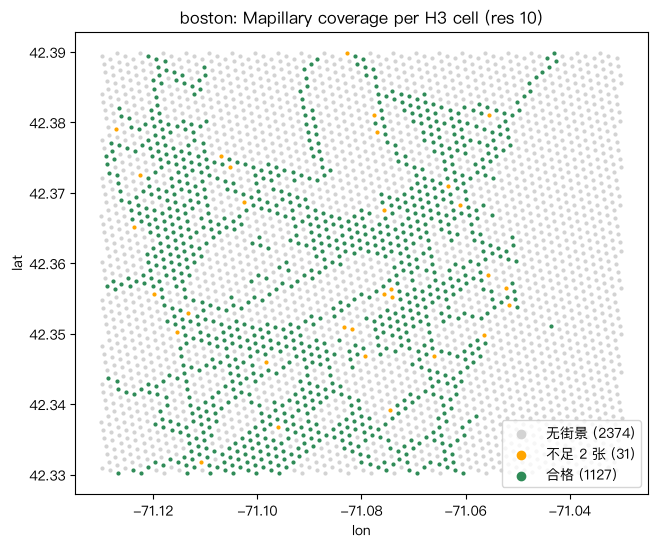

In [ ]:
import matplotlib.pyplot as plt

def build_grid(bbox, res, city, prefix):
    lo0, la0, lo1, la1 = bbox
    poly = h3.LatLngPoly([(la0, lo0), (la0, lo1), (la1, lo1), (la1, lo0)])
    rows = []
    for c in sorted(h3.polygon_to_cells(poly, res)):
        lat, lon = h3.cell_to_latlng(c)
        rows.append({"cell_id": f"{prefix}_{c}", "city": city, "h3_index": c,
                     "h3_res": res, "lat": lat, "lon": lon})
    return pd.DataFrame(rows)

grid = build_grid(BBOX, H3_RES, CITY, CITY_PREFIX)
write_parquet(grid, path("raw", "grid", f"{CITY}_h3r{H3_RES}.parquet"))

grid = grid.join(per_cell, on="h3_index")
grid["n_images_selected"] = grid.n_images_selected.fillna(0).astype(int)
n_any = int((grid.n_images_selected >= 1).sum())
n_ok = int((grid.n_images_selected >= MIN_IMAGES_PER_CELL).sum())
print(f"网格共 {len(grid)} 个格子")
print(f"  ≥1 张可用街景：{n_any}（{n_any / len(grid):.1%}）")
print(f"  ≥{MIN_IMAGES_PER_CELL} 张可用街景（合格）：{n_ok}（{n_ok / len(grid):.1%}）")

fig, ax = plt.subplots(figsize=(8, 6))
for lo, hi, col, lab in [(0, 0, "lightgray", "无街景"),
                         (1, MIN_IMAGES_PER_CELL - 1, "orange", f"不足 {MIN_IMAGES_PER_CELL} 张"),
                         (MIN_IMAGES_PER_CELL, 99, "seagreen", "合格")]:
    s = grid[grid.n_images_selected.between(lo, hi)]
    ax.scatter(s.lon, s.lat, s=4, c=col, label=f"{lab} ({len(s)})")
ax.set_aspect(1 / np.cos(np.radians((min_lat + max_lat) / 2)))
ax.set_xlabel("lon"); ax.set_ylabel("lat"); ax.legend(markerscale=3)
ax.set_title(f"{CITY}: Mapillary coverage per H3 cell (res {H3_RES})")
plt.show()

## 9. 抽样并写出格子表
从合格格子里随机抽 `SAMPLE_SIZE` 个（固定随机种子）。`cells.parquet` 是**格子主表**，每次运行会整体重写；
后面的 notebook 往里补列（卫星图路径等）。`cell_id` 由 `h3_index` 派生，所以换范围、换样本数都不会变。

In [ ]:
eligible = grid[grid.n_images_selected >= MIN_IMAGES_PER_CELL]
if SAMPLE_SIZE and SAMPLE_SIZE < len(eligible):
    cells = eligible.sample(n=SAMPLE_SIZE, random_state=SEED)
else:
    cells = eligible
cells = cells.sort_values("cell_id").reset_index(drop=True)
cells["capture_min"] = cells.capture_min.dt.strftime("%Y-%m")
cells["capture_max"] = cells.capture_max.dt.strftime("%Y-%m")

sv = selected[selected.h3_index.isin(cells.h3_index)].copy()
sv["cell_id"] = f"{CITY_PREFIX}_" + sv.h3_index
sv["captured_at"] = sv.captured_at.dt.strftime("%Y-%m-%dT%H:%M:%SZ")
sv["image_path"] = [f"raw/mapillary/images/{i}.jpg" for i in sv.image_id]   # 相对数据根目录的路径
sv = sv[["image_id", "cell_id", "h3_index", "lat", "lon", "captured_at", "compass", "quadrant",
         "is_pano", "sequence", "image_path"]].sort_values(["cell_id", "image_id"]).reset_index(drop=True)
print(f"抽到 {len(cells)} 个格子，共 {len(sv)} 张街景")
cells.head()

抽到 1127 个格子，共 4429 张街景


,cell_id,city,h3_index,h3_res,lat,lon,n_images_selected,n_quadrants,capture_min,capture_max,n_images_filtered
0,BOS_8a2a3064000ffff,boston,8a2a3064000ffff,10,42.330223,-71.126674,4,2.0,2022-07,2024-04,22.0
1,BOS_8a2a3064014ffff,boston,8a2a3064014ffff,10,42.330228,-71.122261,4,2.0,2021-04,2024-04,29.0
2,BOS_8a2a3064015ffff,boston,8a2a3064015ffff,10,42.330610,-71.123829,4,2.0,2021-04,2024-04,44.0
3,BOS_8a2a3064016ffff,boston,8a2a3064016ffff,10,42.330997,-71.120983,4,2.0,2021-04,2024-04,47.0
4,BOS_8a2a30640807fff,boston,8a2a30640807fff,10,42.336760,-71.118017,4,2.0,2020-08,2020-08,7.0


## 10. 下载街景图片
对入选的每张图，先用 id 现取一个新的图片链接（1024 px 缩略图，对 VLM 打分足够），再下载。用 `DOWNLOAD_WORKERS` 个线程并发，已存在的文件直接跳过，单张失败不会中断整批。

In [ ]:
def fetch_image(image_id, out_path):
    js = mapillary_get(f"{API}/{image_id}", {"access_token": TOKEN, "fields": "thumb_1024_url"})
    url = js.get("thumb_1024_url")
    data = download_bytes(url) if url else None
    if data is None:
        return False
    with fs.open(path(out_path), "wb") as f:
        f.write(data)
    return True

def download_one(r):
    # 返回这张图是否已经在磁盘上；失败只记录，不让整批中断
    try:
        return bool(fs.exists(path(r.image_path)) or fetch_image(r.image_id, r.image_path))
    except Exception as e:
        print(f"  图片 {r.image_id} 下载失败：{repr(e)[:120]}")
        return False

sv["downloaded"] = False
if DOWNLOAD_IMAGES:
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(max_workers=DOWNLOAD_WORKERS) as ex:
        sv["downloaded"] = list(tqdm(ex.map(download_one, list(sv.itertuples())), total=len(sv), desc="下载街景"))
print(f"下载成功 {int(sv.downloaded.sum())} / {len(sv)}")

下载街景:   0%|          | 0/4429 [00:00<?, ?it/s]

下载成功 4422 / 4429


## 11. 写出文件
下载失败的图片会被记录（`downloaded=False`），格子的 `n_images` 以**实际下载成功**的为准；不足 `MIN_IMAGES_PER_CELL` 张的格子会被剔除。

In [ ]:
if DOWNLOAD_IMAGES:
    ok = sv[sv.downloaded]
    n_ok_img = ok.groupby("cell_id").size()
    keep = n_ok_img[n_ok_img >= MIN_IMAGES_PER_CELL].index
    sv = sv[sv.cell_id.isin(keep)].reset_index(drop=True)
    cells = cells[cells.cell_id.isin(keep)].reset_index(drop=True)
cells["n_images"] = cells.cell_id.map(sv.groupby("cell_id").size()).astype(int)
cells["updated_at"] = now_iso()

write_parquet(sv, path("processed", "streetview.parquet"))
write_parquet(cells, path("processed", "cells.parquet"))
print(f"cells.parquet：{len(cells)} 个格子；streetview.parquet：{len(sv)} 张图")

cells.parquet：1126 个格子；streetview.parquet：4425 张图


## 12. 质检：随机看几个格子的街景
每行是一个格子的入选街景，标题是 `cell_id 后几位 · 朝向 · 拍摄日期`。看有没有车内拍摄、挡风玻璃反光、严重模糊、夜间。

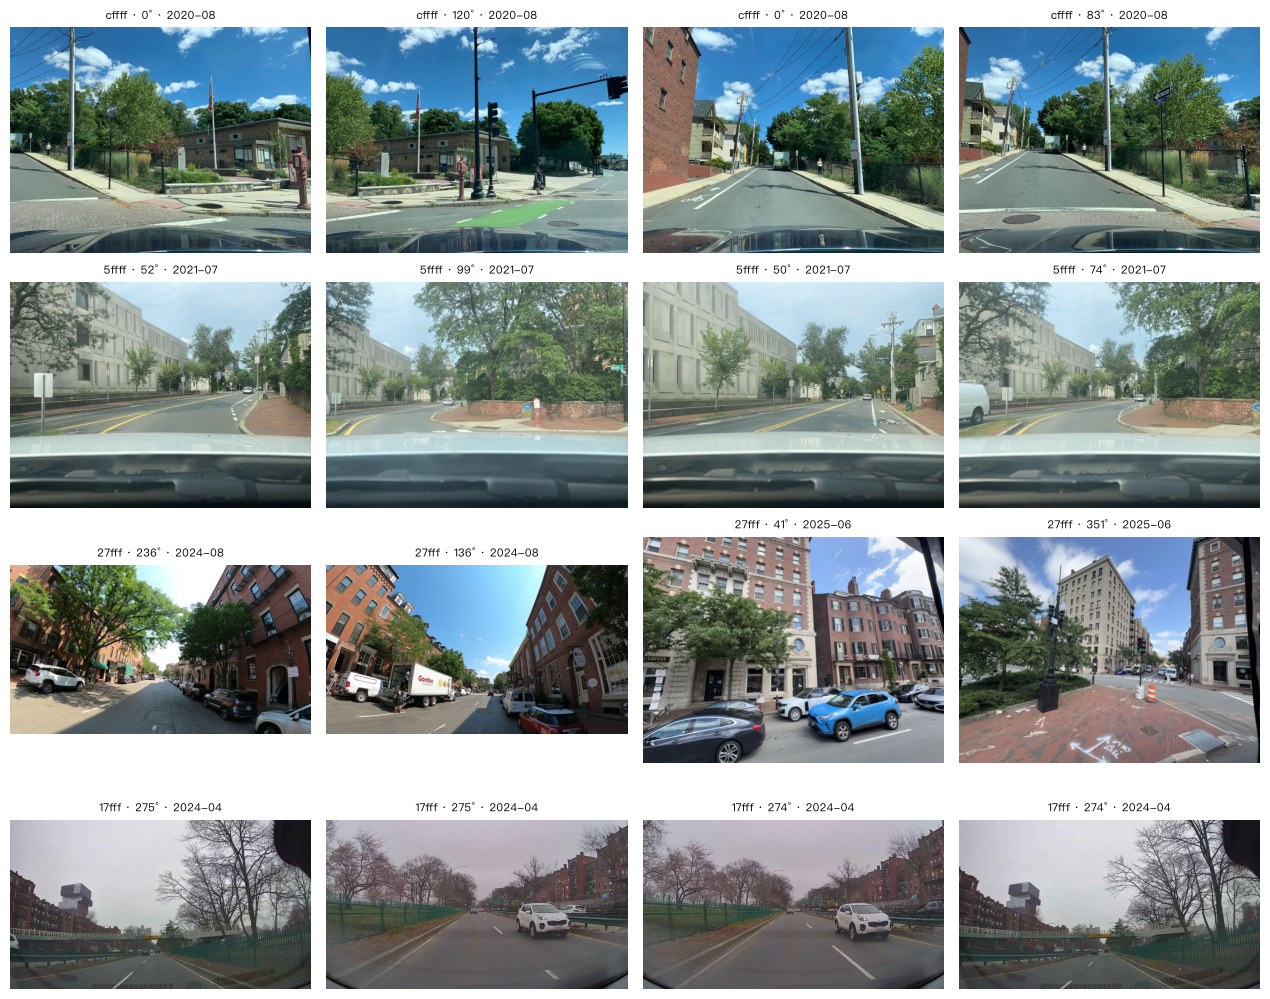

In [ ]:
from PIL import Image

if DOWNLOAD_IMAGES and len(cells):
    show = cells.sample(n=min(4, len(cells)), random_state=SEED).cell_id
    fig, axes = plt.subplots(len(show), MAX_IMAGES_PER_CELL, figsize=(3.2 * MAX_IMAGES_PER_CELL, 2.6 * len(show)))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis("off")
    for r_i, cid in enumerate(show):
        for c_i, r in enumerate(sv[sv.cell_id == cid].head(MAX_IMAGES_PER_CELL).itertuples()):
            with fs.open(path(r.image_path), "rb") as f:
                axes[r_i, c_i].imshow(Image.open(f))
            axes[r_i, c_i].set_title(f"{cid[-5:]} · {r.compass:.0f}° · {r.captured_at[:7]}", fontsize=8)
    plt.tight_layout(); plt.show()

## 13. 运行记录
记下这次用了什么配置、过滤掉多少、覆盖率多少，满足 MS2 “记录每一步用的数据版本”的要求。

In [ ]:
manifest = write_manifest({
    "step": "01_streetview", "city": CITY, "bbox": BBOX, "h3_res": H3_RES,
    "min_year": MIN_YEAR, "exclude_months": list(EXCLUDE_MONTHS), "allow_pano": ALLOW_PANO,
    "min_images_per_cell": MIN_IMAGES_PER_CELL, "max_images_per_cell": MAX_IMAGES_PER_CELL,
    "sample_size": SAMPLE_SIZE, "seed": SEED,
    "filter_funnel": dict(funnel),
    "grid_cells": int(len(grid)), "cells_with_any_image": n_any, "cells_eligible": n_ok,
    "coverage_eligible_frac": round(n_ok / len(grid), 4),
    "cells_sampled": int(len(cells)), "images_selected": int(len(sv)),
    "images_downloaded": int(sv.downloaded.sum()),
    "attribution": "Street-level imagery © Mapillary contributors, CC-BY-SA 4.0",
    "outputs": ["raw/grid", "raw/mapillary", "processed/streetview.parquet", "processed/cells.parquet"],
    "finished_at": now_iso(),
}, "01_streetview_manifest.json")
print(json.dumps(manifest, indent=2, ensure_ascii=False))

{
  "step": "01_streetview",
  "city": "boston",
  "bbox": [
    -71.13,
    42.33,
    -71.03,
    42.39
  ],
  "h3_res": 10,
  "min_year": 2019,
  "exclude_months": [
    12,
    1,
    2,
    3
  ],
  "allow_pano": false,
  "min_images_per_cell": 2,
  "max_images_per_cell": 4,
  "sample_size": 0,
  "seed": 42,
  "filter_funnel": {
    "全部": 1659427,
    "在 BBOX 内": 1427893,
    "拍摄于 2019 年及以后": 452028,
    "排除 (12, 1, 2, 3) 月": 135419,
    "非全景图": 99766,
    "有朝向信息": 99766
  },
  "grid_cells": 3532,
  "cells_with_any_image": 1158,
  "cells_eligible": 1127,
  "coverage_eligible_frac": 0.3191,
  "cells_sampled": 1126,
  "images_selected": 4425,
  "images_downloaded": 4421,
  "attribution": "Street-level imagery © Mapillary contributors, CC-BY-SA 4.0",
  "outputs": [
    "raw/grid",
    "raw/mapillary",
    "processed/streetview.parquet",
    "processed/cells.parquet"
  ],
  "finished_at": "2026-10-12T23:06:56Z"
}


## 下一步
- 50 个格子没问题后，把 `SAMPLE_SIZE` 改成 `0` 跑全部合格格子（街景图片数量会多很多，注意下载时间和磁盘）。
- 看第 8 节的覆盖率图：街景集中在哪里？郊区有多少？如果合格格子太少，可以放宽 `EXCLUDE_MONTHS`、`MIN_YEAR`，或把 `H3_RES` 改成 9（格子更大，更容易凑够 2 张）。
- 下一个 notebook：`02_tiles`，读取 `processed/cells.parquet`，给这些格子裁 NAIP 卫星图。